In [1]:
import pandas as pd
import numpy as np
%matplotlib inline
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('Customer Churn.csv')
df.head(6)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes


# Inspecting Data

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Replacing Blank vlues in TotalCharges with 0 and changing its dtype from object to float

In [6]:
df['TotalCharges']=df['TotalCharges'].replace(" ","0")
df['TotalCharges']=df['TotalCharges'].astype(float)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Checking for null values

In [9]:
df.isnull().sum().sum()

0

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [11]:
df.duplicated().sum()

0

In [12]:
df['customerID'].duplicated().sum()

0

Converting 1 and 0 values to 'senior citizen' and 'not senior citizen'.

In [14]:
def chng(a):
    if a == 1:
        return 'senior citizen'
    else:
        return 'not senior citizen'

df['SeniorCitizen']=df['SeniorCitizen'].apply(chng)

In [15]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,not senior citizen,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,not senior citizen,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,not senior citizen,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,not senior citizen,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,not senior citizen,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [16]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


# Visualizing Data

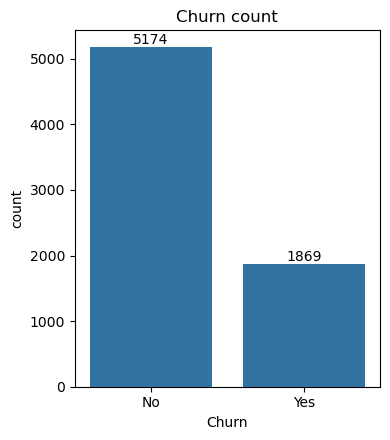

In [18]:
plt.figure(figsize=(4,4.5))
ax=sns.countplot(x='Churn',data=df)
plt.title("Churn count")
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

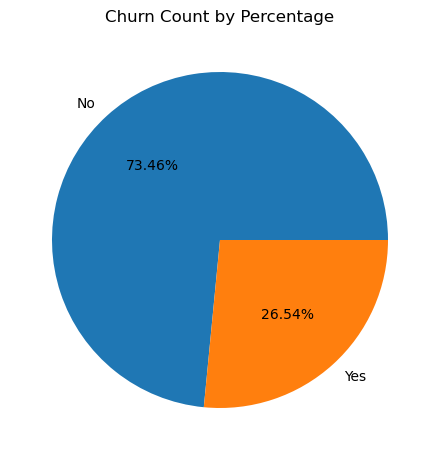

In [19]:
plt.figure(figsize=(4.5,9))
gb=df.groupby('Churn').agg({'Churn':'count'})
plt.pie(gb['Churn'],labels=gb.index,autopct='%1.2f%%')
plt.title('Churn Count by Percentage')
plt.tight_layout()
plt.show()

from above fig. we can conlude that 26.54% people have churned
lets see the reason behind it

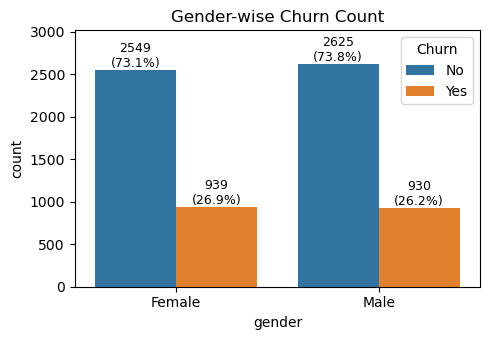

In [21]:
plt.figure(figsize=(5, 3.5))
ax = sns.countplot(x='gender', data=df, hue='Churn')
plt.title("Gender-wise Churn Count")

gender_totals = df['gender'].value_counts().to_dict()

max_height = 0  # track the tallest bar

for bars in ax.containers:
    for bar in bars:
        count = int(bar.get_height())
        x_pos = bar.get_x() + bar.get_width() / 2
        gender_index = int(x_pos + 0.5)

        gender_label = ax.get_xticklabels()[gender_index].get_text()
        total = gender_totals[gender_label]
        percent = (count / total) * 100

        if count > max_height:
            max_height = count

        ax.annotate(f'{count}\n({percent:.1f}%)',
                    xy=(x_pos, bar.get_height()),
                    ha='center', va='bottom', fontsize=9)

plt.ylim(0, max_height * 1.15)

plt.tight_layout()
plt.show()


From above chart we can conclude that Churn rates are nearly identical across genders

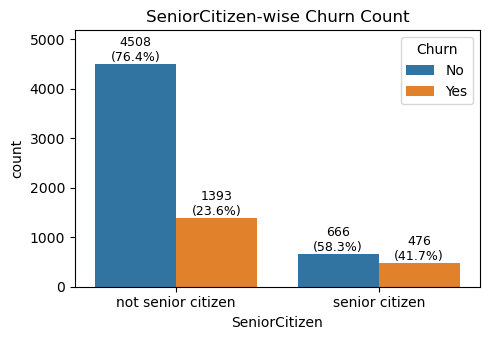

In [23]:
plt.figure(figsize=(5, 3.5))
ax = sns.countplot(x='SeniorCitizen', data=df, hue='Churn')
plt.title("SeniorCitizen-wise Churn Count")


SeniorCitizen_totals = df['SeniorCitizen'].value_counts().to_dict()

max_height = 0  # track the tallest bar

for bars in ax.containers:
    for bar in bars:
        count = int(bar.get_height())
        x_pos = bar.get_x() + bar.get_width() / 2
        SeniorCitizen_index = int(x_pos + 0.5)

        SeniorCitizen_label = ax.get_xticklabels()[SeniorCitizen_index].get_text()
        total = SeniorCitizen_totals[SeniorCitizen_label]
        percent = (count / total) * 100

        if count > max_height:
            max_height = count

        ax.annotate(f'{count}\n({percent:.1f}%)',
                    xy=(x_pos, bar.get_height()),
                    ha='center', va='bottom', fontsize=9)

plt.ylim(0, max_height * 1.15)

plt.tight_layout()
plt.show()

From above chart we can conclude that "Though fewer in number, Senior Citizens show a higher tendency to churn."

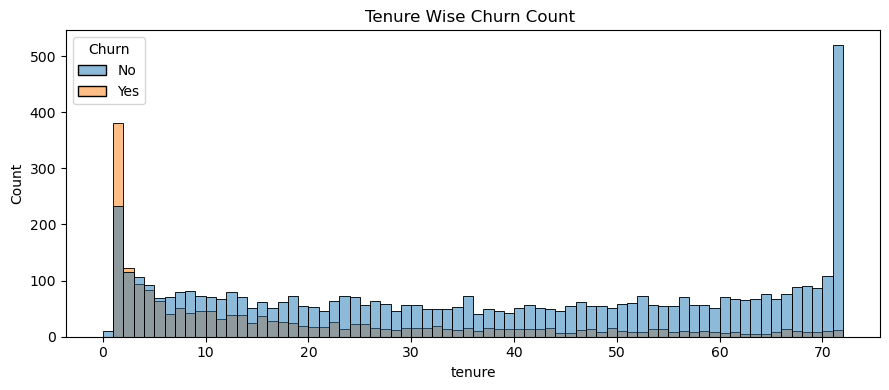

In [25]:
plt.figure(figsize=(9,4))
ax=sns.histplot(x='tenure',data=df,hue="Churn",bins=72)
plt.title("Tenure Wise Churn Count ")
plt.tight_layout()
plt.show()

From above chart we can conclude that shorter tenures have higher churn rates

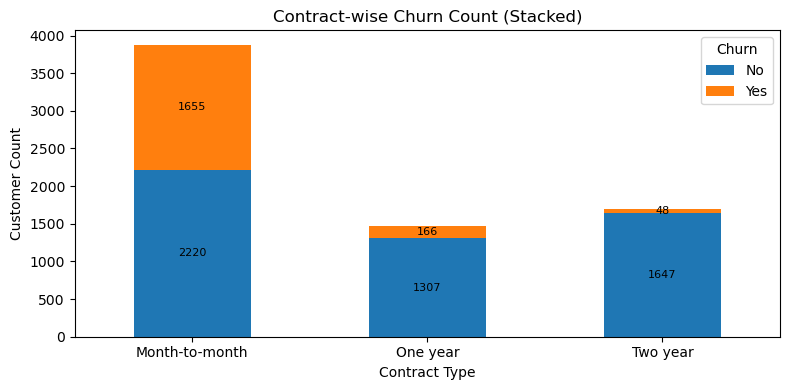

In [27]:
contract_churn = df.groupby(['Contract', 'Churn']).size().unstack(fill_value=0)
ax = contract_churn.plot(kind='bar', stacked=True, figsize=(8, 4))
for container in ax.containers:
    for bar in container:
        height = bar.get_height()
        if height > 0:  
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + height / 2,
                f'{int(height)}',
                ha='center', va='center',
                fontsize=8, color='black'
            )
plt.title("Contract-wise Churn Count (Stacked)")
plt.xlabel("Contract Type")
plt.ylabel("Customer Count")
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.tight_layout()
plt.show()


From above chart we can conclude that Longer contracts have lower churn rates

In [29]:
df.columns.values

array(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges',
       'TotalCharges', 'Churn'], dtype=object)

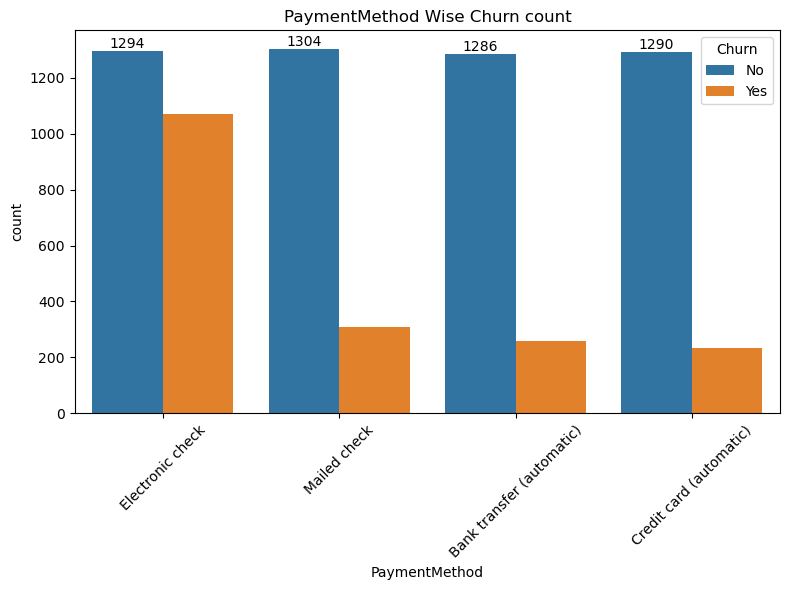

In [30]:
plt.figure(figsize=(8,6))
ax=sns.countplot(x='PaymentMethod',data=df,hue='Churn')
plt.title("PaymentMethod Wise Churn count")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Customers using electronic checks show the highest churn rate, while those paying via automatic methods like bank transfer or credit card have significantly lower churn. This suggests automation may boost customer retention by enhancing convenience and consistency.

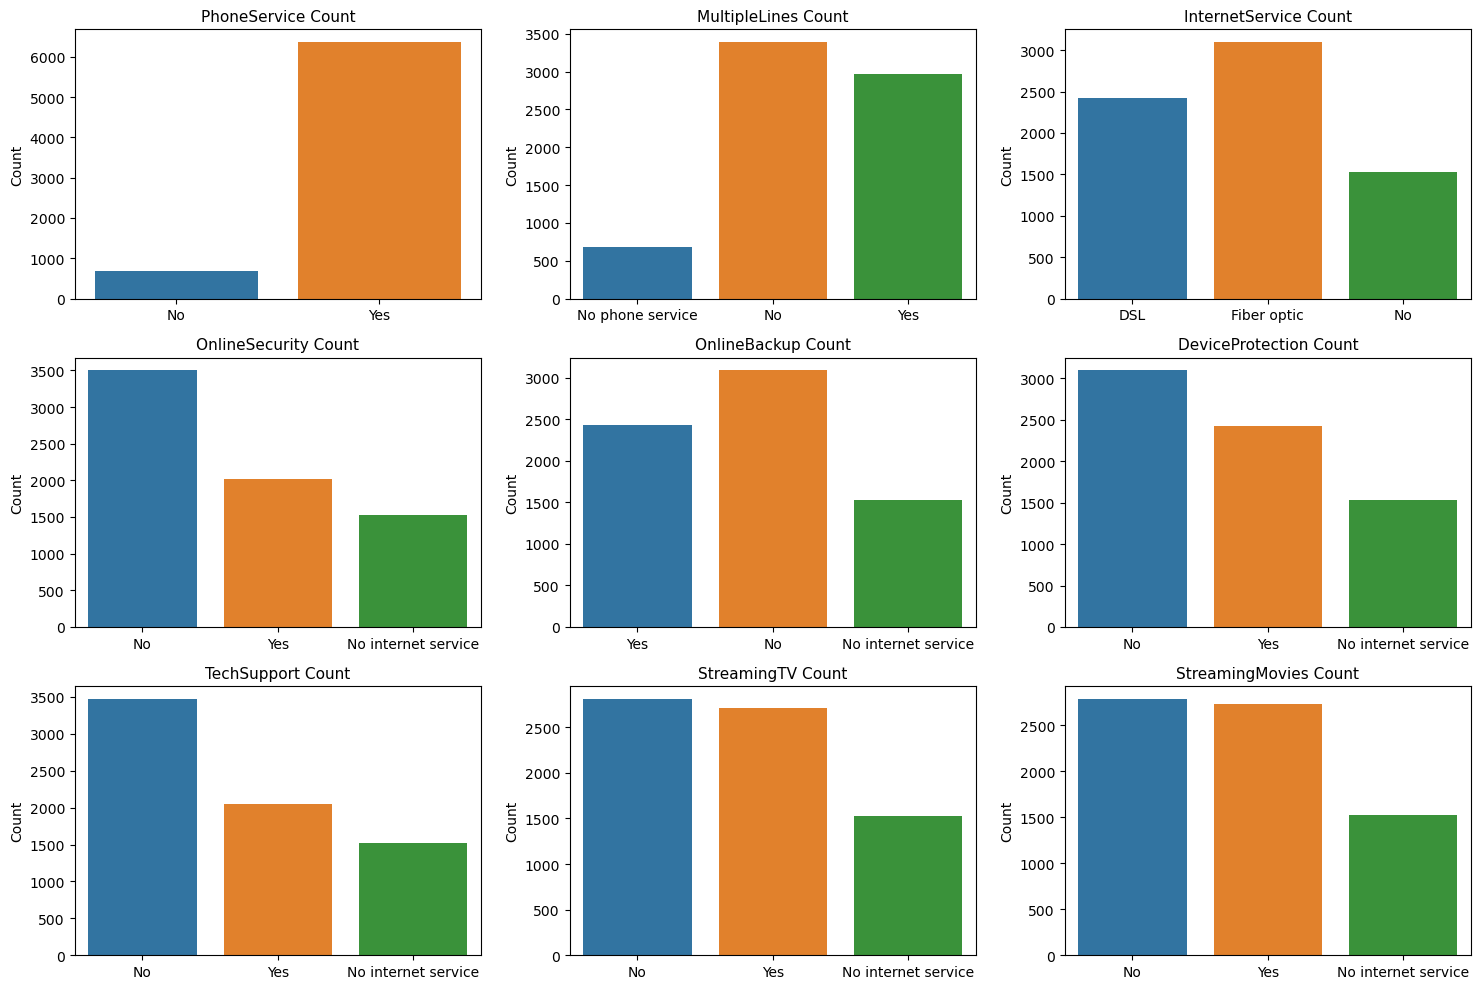

In [32]:
cols = ['PhoneService', 'MultipleLines', 'InternetService',
        'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies']
rows = 3
cols_per_row = 3
fig, axes = plt.subplots(rows, cols_per_row, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(cols):
    sns.countplot(data=df, x=col, hue=col, ax=axes[i], legend=False)
    axes[i].set_title(f'{col} Count', fontsize=11)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x')
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

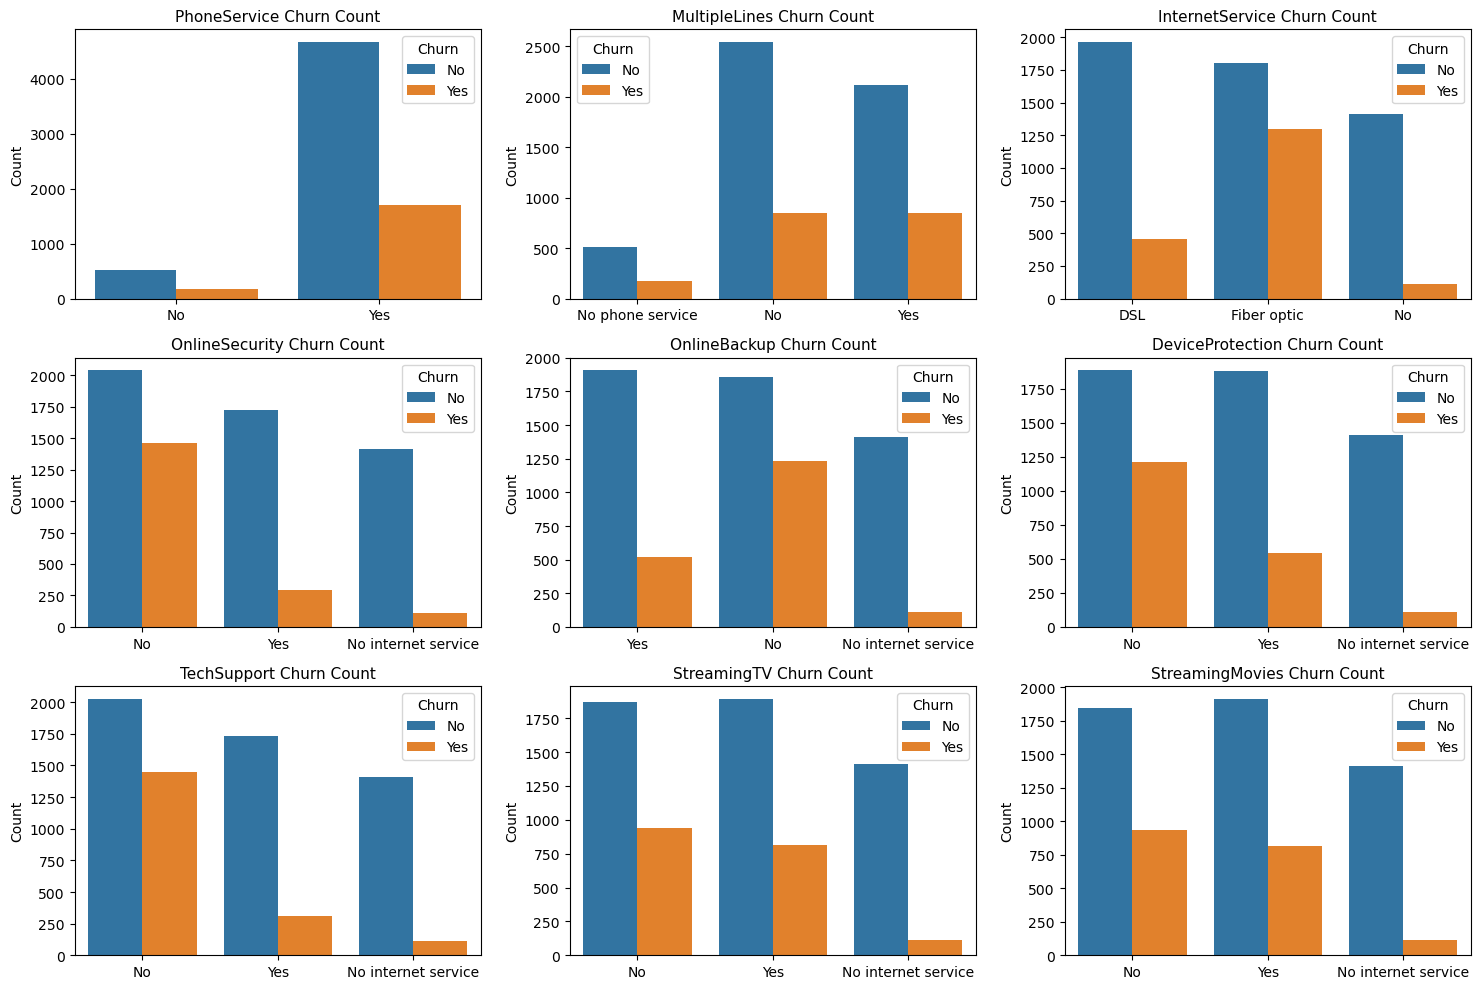

In [33]:
cols = ['PhoneService', 'MultipleLines', 'InternetService',
        'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies']
rows = 3
cols_per_row = 3
fig, axes = plt.subplots(rows, cols_per_row, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(cols):
    sns.countplot(data=df, x=col, hue="Churn", ax=axes[i], legend= True)
    axes[i].set_title(f'{col} Churn Count', fontsize=11)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x')
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

The plots reveal that churn is significantly higher among users who lack additional services like online security, tech support, and device protection. Customers without internet or with fiber optic connections show notably higher churn, indicating service quality and feature availability may strongly influence retention.